# A1 — Baseline and hyperparameter optimisation

Train on 2017–2020, validate on 2021, and test on 2022. Ray Tune searches the 25 required combinations.

In [1]:
import copy
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import ray
import torch
from ray import tune
from torch import nn
from torch.utils.data import DataLoader

PART_A = Path.cwd()
if PART_A.name != "part-a":
    PART_A = PART_A / "part-a"
sys.path.append(str(PART_A / "src"))

from config import Config
from data import prepare_data
from model import PriceModel

DATA_PATH = PART_A / "hdb_price_prediction.csv"
BASE_CONFIG = Config()
SEED = BASE_CONFIG.seed
BATCH_SIZE = BASE_CONFIG.batch_size
LEARNING_RATE = BASE_CONFIG.learning_rate
MAX_EPOCHS = BASE_CONFIG.max_epochs
PATIENCE = BASE_CONFIG.early_stopping_patience
MIN_IMPROVEMENT = BASE_CONFIG.early_stopping_threshold
HIDDEN_WIDTHS = [16, 32, 64, 128, 256]
EMBEDDING_DIMS = [2, 4, 8, 12, 16]
torch.set_num_threads(1)

d:\001-Code\NTU-Study\SC4001\sc4001-individual-assignment\part-a\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-03 18:20:49,078	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-03 18:21:02,846	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


## Model and data

In [2]:
data = prepare_data(DATA_PATH, BASE_CONFIG)
print(f"Training rows: {len(data['train']):,}")
print(f"Validation rows: {len(data['validation']):,}")
print(f"Test rows: {len(data['test']):,}")

Training rows: 87,370
Validation rows: 29,057
Test rows: 26,702


## Number of trainable parameters

In [3]:
torch.manual_seed(SEED)
baseline_model = PriceModel(
    data["cardinalities"], data["target_mean"], data["target_std"], BASE_CONFIG
)

for name, parameter in baseline_model.named_parameters():
    if parameter.requires_grad:
        print(name, tuple(parameter.shape), parameter.numel())

total = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total:,}")

embeddings.0.weight (13, 8) 104
embeddings.1.weight (27, 8) 216
embeddings.2.weight (44, 8) 352
embeddings.3.weight (18, 8) 144
mlp.0.weight (64, 38) 2432
mlp.0.bias (64,) 64
mlp.1.weight (64,) 64
mlp.1.bias (64,) 64
mlp.3.weight (1, 64) 64
mlp.3.bias (1,) 1
Total trainable parameters: 3,505


## Training functions

In [4]:
def set_seed():
    torch.manual_seed(SEED)
    torch.use_deterministic_algorithms(True, warn_only=True)


@torch.no_grad()
def predict(model, dataset):
    model.eval()
    predictions, targets = [], []
    for categorical, continuous, target in DataLoader(dataset, batch_size=BATCH_SIZE):
        predictions.append(model.predict_price(categorical, continuous))
        targets.append(target)
    return torch.cat(predictions), torch.cat(targets)


def rmse(model, dataset):
    prediction, target = predict(model, dataset)
    return (prediction - target).square().mean().sqrt().item()


def r2(model, dataset):
    prediction, target = predict(model, dataset)
    residual_sum = (prediction - target).square().sum()
    total_sum = (target - target.mean()).square().sum()
    return (1 - residual_sum / total_sum).item()


def train_model(model, training_data, evaluation_data, epochs=MAX_EPOCHS, early_stopping=True):
    set_seed()
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(
        training_data, batch_size=BATCH_SIZE, shuffle=True, generator=generator
    )
    optimiser = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.MSELoss()
    history = []
    best_rmse = float("inf")
    best_epoch = 0
    best_weights = None
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        model.train()
        for categorical, continuous, target in loader:
            optimiser.zero_grad()
            standard_target = (target - model.target_mean) / model.target_std
            loss = loss_function(model(categorical, continuous), standard_target)
            loss.backward()
            optimiser.step()

        train_rmse = rmse(model, training_data)
        evaluation_rmse = rmse(model, evaluation_data)
        history.append((epoch, train_rmse, evaluation_rmse))

        if early_stopping:
            if evaluation_rmse < best_rmse - MIN_IMPROVEMENT:
                best_rmse = evaluation_rmse
                best_epoch = epoch
                best_weights = copy.deepcopy(model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
                if epochs_without_improvement == PATIENCE:
                    break

    if early_stopping:
        model.load_state_dict(best_weights)
    else:
        best_epoch = epochs
        best_rmse = history[-1][2]

    return history, best_epoch, best_rmse

## Ray Tune grid search

In [5]:
def train_trial(choice, train_data, validation_data, cardinalities, target_mean, target_std):
    torch.set_num_threads(1)
    set_seed()
    embedding_dim = choice["embedding_dim"]
    config = replace(
        BASE_CONFIG,
        hidden_width=choice["hidden_width"],
        embedding_dims=(embedding_dim,) * len(BASE_CONFIG.categorical_features),
    )
    model = PriceModel(cardinalities, target_mean, target_std, config)
    _, best_epoch, best_rmse = train_model(
        model, train_data, validation_data, MAX_EPOCHS
    )
    tune.report({"validation_rmse": best_rmse, "best_epoch": best_epoch})


ray.shutdown()
ray.init(
    num_cpus=4,
    include_dashboard=False,
    runtime_env={"env_vars": {"PYTHONPATH": str(PART_A / "src")}},
)
trainable = tune.with_parameters(
    train_trial,
    train_data=data["train"],
    validation_data=data["validation"],
    cardinalities=data["cardinalities"],
    target_mean=data["target_mean"],
    target_std=data["target_std"],
)
tuner = tune.Tuner(
    tune.with_resources(trainable, {"cpu": 1}),
    param_space={
        "hidden_width": tune.grid_search(HIDDEN_WIDTHS),
        "embedding_dim": tune.grid_search(EMBEDDING_DIMS),
    },
    tune_config=tune.TuneConfig(
        metric="validation_rmse", mode="min", max_concurrent_trials=4
    ),
    run_config=tune.RunConfig(
        storage_path=str((PART_A / "outputs" / "ray").resolve()), verbose=1
    ),
)
results = tuner.fit()
ray.shutdown()

(raylet) Stack (most recent call first):
(raylet)   File "d:\001-Code\NTU-Study\SC4001\sc4001-individual-assignment\part-a\.venv\Lib\site-packages\ray\_private\worker.py", line 627 in job_logging_config
(raylet)   File "d:\001-Code\NTU-Study\SC4001\sc4001-individual-assignment\part-a\.venv\Lib\site-packages\ray\_private\worker.py", line 2807 in disconnect
(raylet)   File "d:\001-Code\NTU-Study\SC4001\sc4001-individual-assignment\part-a\.venv\Lib\site-packages\ray\_private\worker.py", line 2118 in shutdown
(raylet)   File "d:\001-Code\NTU-Study\SC4001\sc4001-individual-assignment\part-a\.venv\Lib\site-packages\ray\_private\worker.py", line 1170 in wrapper
2026-10-03 18:29:42,560	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to 'D:/001-Code/NTU-Study/SC4001/sc4001-individual-assignment/part-a/outputs/ray/train_trial_2026-10-03_18-21-20' in 0.0822s.
2026-10-03 18:29:42,576	INFO tune.py:1039 -- Total run time: 502.24 seconds (502.01 seconds for the 

In [7]:
search_results = results.get_dataframe()[
    ["config/hidden_width", "config/embedding_dim", "validation_rmse", "best_epoch"]
].rename(columns={
    "config/hidden_width": "hidden_width",
    "config/embedding_dim": "embedding_dim",
})
display(search_results.pivot(
    index="hidden_width", columns="embedding_dim", values="validation_rmse"
).round(0))

best_result = results.get_best_result(metric="validation_rmse", mode="min")
best_hidden_width = best_result.config["hidden_width"]
best_embedding_dim = best_result.config["embedding_dim"]
print(f"Best hidden width: {best_hidden_width}")
print(f"Best embedding dimension: {best_embedding_dim}")
print(f"Best validation RMSE: SGD {best_result.metrics['validation_rmse']:,.2f}")

embedding_dim,2,4,8,12,16
hidden_width,,,,,
16,65190.0,64673.0,64185.0,65347.0,66107.0
32,64021.0,64763.0,63221.0,63752.0,61598.0
64,64970.0,64376.0,62081.0,60785.0,60505.0
128,62393.0,62755.0,62612.0,59732.0,60961.0
256,62909.0,58657.0,61123.0,61691.0,60592.0


Best hidden width: 256
Best embedding dimension: 4
Best validation RMSE: SGD 58,656.77


## Training and validation curves for the selected model

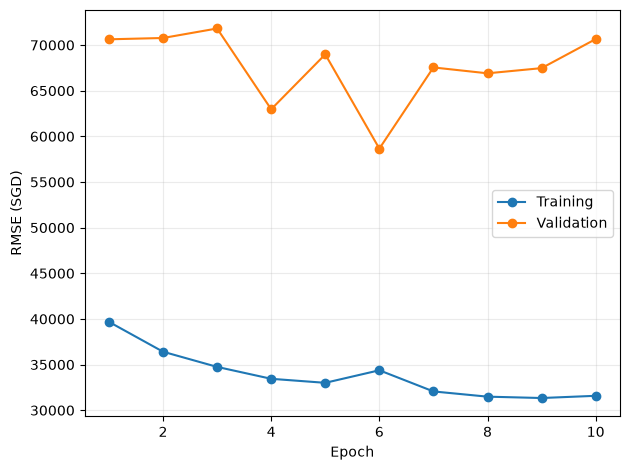

Selected epoch: 6
Validation RMSE: SGD 58,656.77


In [8]:
selected_config = replace(
    BASE_CONFIG,
    hidden_width=best_hidden_width,
    embedding_dims=(best_embedding_dim,) * len(BASE_CONFIG.categorical_features),
)
set_seed()
selected_model = PriceModel(
    data["cardinalities"], data["target_mean"], data["target_std"], selected_config
)
selected_history, selected_epoch, selected_validation_rmse = train_model(
    selected_model, data["train"], data["validation"], MAX_EPOCHS
)

plt.figure()
epochs = [row[0] for row in selected_history]
plt.plot(epochs, [row[1] for row in selected_history], marker="o", label="Training")
plt.plot(epochs, [row[2] for row in selected_history], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("RMSE (SGD)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(PART_A / "a1_train_validation_rmse.png", dpi=200)
plt.show()
print(f"Selected epoch: {selected_epoch}")
print(f"Validation RMSE: SGD {selected_validation_rmse:,.2f}")

## Retrain on 2017–2021 and evaluate on 2022

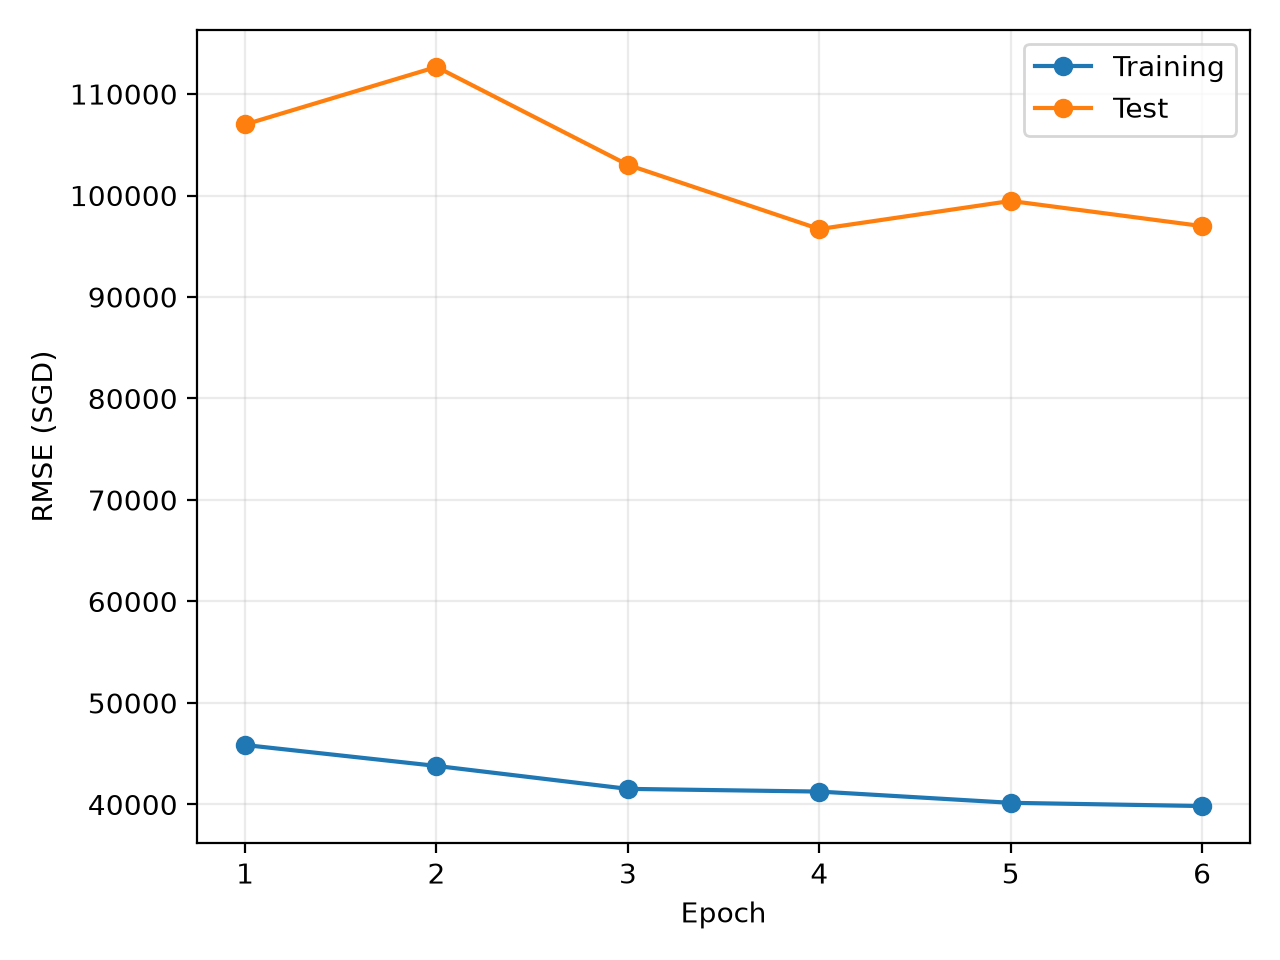

Final test RMSE: SGD 96,984.81
Final test R²: 0.6755


In [ ]:
final_config = replace(
    BASE_CONFIG,
    train_years=(2017, 2018, 2019, 2020, 2021),
    validation_year=2022,
)
final_data = prepare_data(DATA_PATH, final_config)

set_seed()
final_model = PriceModel(
    final_data["cardinalities"],
    final_data["target_mean"],
    final_data["target_std"],
    selected_config,
)
final_history, _, _ = train_model(
    final_model, final_data["train"], final_data["validation"],
    epochs=selected_epoch, early_stopping=False,
)

plt.figure()
epochs = [row[0] for row in final_history]
plt.plot(epochs, [row[1] for row in final_history], marker="o", label="Training")
plt.plot(epochs, [row[2] for row in final_history], marker="o", label="Test")
plt.xlabel("Epoch")
plt.ylabel("RMSE (SGD)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(PART_A / "a1_train_test_rmse.png", dpi=200)
plt.show()

print(f"Final test RMSE: SGD {rmse(final_model, final_data['validation']):,.2f}")
print(f"Final test R²: {r2(final_model, final_data['validation']):.4f}")